# 03 · İmputasyon ve Modelleme: Göstergeli mi, Göstergesiz mi?

**Görseldeki 2. adım:** *Göstergeli ve göstergesiz imputasyonun Pipeline içinde karşılaştırılması.*

02'de eksikliğin rastgele olmadığını ve hedefle ilişkili olduğunu gördük. Şimdi şunu soruyoruz: **Eksikliğin bilgisini modele vermek tahmini iyileştiriyor mu?**

### Karşılaştırılan 5 ön işleme düzeni

| Kod | İmputasyon | Eksiklik göstergesi | Açıklama |
|---|---|---|---|
| **A** | Medyan | Yok | Referans: eksiklik bilgisi kaybolur |
| **B** | Medyan | Sütun başına (sklearn `add_indicator`) | 11 gösterge; HK/RİA/CYBH'ninkiler neredeyse aynı |
| **C** | Medyan | Grup başına (7 gösterge) | 02'deki gruplar; tekrar yok |
| **D** | MICE (`IterativeImputer`) | Yok | Eksik değer diğer sütunlardan tahmin edilir |
| **E** | MICE | Grup başına | D + C'deki göstergeler |

### İki model
- **Lojistik regresyon (LR):** Basit, yorumlanabilir, klinik risk modellerinde standart.
- **Rastgele orman (RF):** Doğrusal olmayan ilişkileri ve etkileşimleri yakalar.

### Değerlendirme düzeni
- **5 katlı katmanlı çapraz doğrulama × 10 tekrar = 50 kat.** Her katta 55 pozitifin ≈11'i test kümesinde olur. Tek bir bölmenin sonucu çok oynak olacağı için tekrarlıyoruz.
- **Metrikler:**
  - **PR-AUC** (ortalama kesinlik): Nadir sınıfta asıl metrik. Rastgele modelin PR-AUC'u = pozitif oranı ≈ **0.064**.
  - **ROC-AUC:** Sıralama başarısı. Rastgele = 0.5.
  - **Brier skoru:** Olasılık tahminlerinin hatası (düşük = iyi). Herkese %6.4 diyen modelin Brier skoru ≈ **0.060**.
- **Sızıntı yok:** Medyan, MICE modeli ve ölçekleme her katta yalnızca **eğitim** kısmından öğrenilir (`Pipeline`).

In [1]:
import sys
sys.path.append("..")
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

from src.utils import load_raw, clean, build_pipeline, corrected_ttest, FEATURES, NUMERIC, TARGET

pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", font_scale=0.9)
FIG = Path("../results/figures")
TAB = Path("../results/tables")

## 1. Veri

In [2]:
df = clean(load_raw())
X = df[FEATURES]          # 36 sütundan 01'de seçilen 15 öznitelik (sütun silme burada)
y = df[TARGET]

print("X:", X.shape, "  |  biyopsi+:", int(y.sum()), f"(%{y.mean()*100:.1f})")
print("Sayısal (log1p uygulanır):", NUMERIC)
print("İkili (0/1):", [c for c in FEATURES if c not in NUMERIC])
print("\nEksik değer içeren sütun sayısı:", int(X.isna().any().sum()), "  |  toplam eksik hücre:", int(X.isna().sum().sum()))

X: (858, 15)   |  biyopsi+: 55 (%6.4)
Sayısal (log1p uygulanır): ['Age', 'Number of sexual partners', 'First sexual intercourse', 'Num of pregnancies', 'Smokes (years)', 'Smokes (packs/year)', 'Hormonal Contraceptives (years)', 'IUD (years)', 'STDs (number)']
İkili (0/1): ['STDs:condylomatosis', 'STDs:syphilis', 'STDs:HIV', 'Dx:Cancer', 'Dx:CIN', 'Dx:HPV']

Eksik değer içeren sütun sayısı: 11   |  toplam eksik hücre: 762


## 2. Pipeline'ın yapısı

`src/utils.py` içindeki `build_pipeline()` fonksiyonu şu adımları kurar:

```
            ┌─ log1p (sayısal sütunlar) → imputasyon → standartlaştırma ─┐
X (15 sütun)┤                                                             ├─→ model
            └─ grup eksiklik göstergeleri (C ve E'de) ───────────────────┘
```

- **log1p:** Sigara yılı gibi çok çarpık sütunları sıkıştırır (`log(1+x)`, 0 → 0). LR için faydalı, RF için zararsız.
- **Medyan imputasyonu ikili sütunlarda da doğru çalışır:** 0/1 sütunlarda 1'lerin oranı %50'nin altında olduğu sürece medyan = 0 = en sık değer.
- **Göstergeler imputasyondan önce, ham veriden hesaplanır**; yani "bu değer aslında boştu" bilgisi korunur.

### 2a. Önizleme: doldurulmuş veri nasıl görünüyor?

> ⚠️ Bu hücre **sadece göstermek için** Pipeline'ı tüm veriye uyduruyor. Modelleri değerlendirirken bunu **kullanmıyoruz**; orada her kat kendi eğitim verisiyle ayrı uydurulacak.

In [3]:
preview_pipe = build_pipeline(LogisticRegression(), imputer="median", indicator=False, group=True)
ozellik = preview_pipe.named_steps["ozellik"].fit(X)
cols = [c.split("__", 1)[1] for c in ozellik.get_feature_names_out()]
Xt = pd.DataFrame(ozellik.transform(X), columns=cols, index=X.index)

# HK sorusunu cevaplamamış birkaç hasta: önce ve sonra
idx = X[X["Hormonal Contraceptives (years)"].isna()].index[:3]
show = ["Age", "Hormonal Contraceptives (years)", "IUD (years)", "STDs (number)"]
print("ÖNCE (ham):")
display(X.loc[idx, show])
print("SONRA (log1p + medyan + standartlaştırma, + göstergeler):")
display(Xt.loc[idx, show + [c for c in cols if c.startswith("eksik_")]].round(2))
print("Toplam sütun:", Xt.shape[1], "=", len(FEATURES), "öznitelik +", Xt.shape[1] - len(FEATURES), "gösterge  |  kalan NaN:", int(Xt.isna().sum().sum()))

ÖNCE (ham):


,Age,Hormonal Contraceptives (years),IUD (years),STDs (number)
71,34,NaN,NaN,NaN
74,35,NaN,NaN,NaN
90,36,NaN,NaN,NaN


SONRA (log1p + medyan + standartlaştırma, + göstergeler):


,Age,Hormonal Contraceptives (years),IUD (years),STDs (number),eksik_Partner,eksik_İlk ilişki,eksik_Gebelik,eksik_Sigara,eksik_HK,eksik_RİA,eksik_CYBH
71,0.95,-0.37,-0.29,-0.31,1.0,1.0,0.0,0.0,1.0,1.0,1.0
74,1.05,-0.37,-0.29,-0.31,0.0,0.0,0.0,0.0,1.0,1.0,1.0
90,1.14,-0.37,-0.29,-0.31,0.0,0.0,0.0,0.0,1.0,1.0,1.0


Toplam sütun: 22 = 15 öznitelik + 7 gösterge  |  kalan NaN: 0


Boşluklar doldu; değerler standartlaştırıldığı için artık ortalama 0, standart sapma 1 civarında. `eksik_HK`, `eksik_RİA`, `eksik_CYBH` sütunları bu hastalarda **1**: model "bu hasta bu soruları cevaplamadı" bilgisini görebiliyor.

## 3. Modellerin karşılaştırılması

In [4]:
CONFIGS = {
    "A · medyan":            dict(imputer="median", indicator=False, group=False),
    "B · medyan + sütun gös.": dict(imputer="median", indicator=True,  group=False),
    "C · medyan + grup gös.":  dict(imputer="median", indicator=False, group=True),
    "D · MICE":              dict(imputer="mice",   indicator=False, group=False),
    "E · MICE + grup gös.":    dict(imputer="mice",   indicator=False, group=True),
}
MODELS = {
    "LR": LogisticRegression(C=1.0, max_iter=2000),
    "RF": RandomForestClassifier(n_estimators=500, min_samples_leaf=5, n_jobs=-1, random_state=0),
}
SCORING = {"PR-AUC": "average_precision", "ROC-AUC": "roc_auc", "Brier": "neg_brier_score"}

# Aynı random_state → tüm modeller birebir aynı 50 bölme üzerinde test edilir (eşleştirilmiş karşılaştırma)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

def run(name, model_name, estimator, Xdata=X):
    r = cross_validate(estimator, Xdata, y, cv=cv, scoring=SCORING, n_jobs=-1)
    return pd.DataFrame({"model": model_name, "düzen": name, "kat": range(len(r["test_PR-AUC"])),
                         "PR-AUC": r["test_PR-AUC"], "ROC-AUC": r["test_ROC-AUC"], "Brier": -r["test_Brier"]})

folds = []
# Referans çizgileri: hiçbir şey öğrenmeyen model ve sadece yaşı kullanan model
folds.append(run("herkese %6.4", "Referans", DummyClassifier(strategy="prior")))
folds.append(run("sadece yaş", "Referans", LogisticRegression(), X[["Age"]]))

for mname, model in MODELS.items():
    for cname, cfg in CONFIGS.items():
        folds.append(run(cname, mname, build_pipeline(model, **cfg)))
        print(f"✓ {mname} {cname}")

folds = pd.concat(folds, ignore_index=True)

✓ LR A · medyan


✓ LR B · medyan + sütun gös.


✓ LR C · medyan + grup gös.


✓ LR D · MICE


✓ LR E · MICE + grup gös.


✓ RF A · medyan


✓ RF B · medyan + sütun gös.


✓ RF C · medyan + grup gös.


✓ RF D · MICE


✓ RF E · MICE + grup gös.


In [5]:
res = (folds.groupby(["model", "düzen"], sort=False)[["PR-AUC", "ROC-AUC", "Brier"]]
            .agg(["mean", "std"]).round(3))
res.to_csv(TAB / "03_cv_sonuclari.csv", encoding="utf-8-sig")
res

PR-AUC        ROC-AUC         Brier       
                                   mean    std    mean    std   mean    std
model    düzen                                                             
Referans herkese %6.4             0.064  0.000   0.500  0.000  0.060  0.000
         sadece yaş               0.127  0.067   0.562  0.092  0.060  0.001
LR       A · medyan               0.170  0.067   0.600  0.094  0.061  0.004
         B · medyan + sütun gös.  0.153  0.063   0.609  0.081  0.062  0.005
         C · medyan + grup gös.   0.165  0.063   0.622  0.072  0.061  0.005
         D · MICE                 0.165  0.067   0.586  0.093  0.061  0.004
         E · MICE + grup gös.     0.164  0.063   0.616  0.073  0.061  0.005
RF       A · medyan               0.189  0.076   0.663  0.082  0.058  0.002
         B · medyan + sütun gös.  0.192  0.073   0.686  0.073  0.058  0.002
         C · medyan + grup gös.   0.194  0.076   0.693  0.070  0.058  0.002
         D · MICE                 0.193  0.078   0.666  0.080  0.058  0.002
         E · MICE + grup gös.     0.193  0.075   0.681  0.074  0.058  0.002

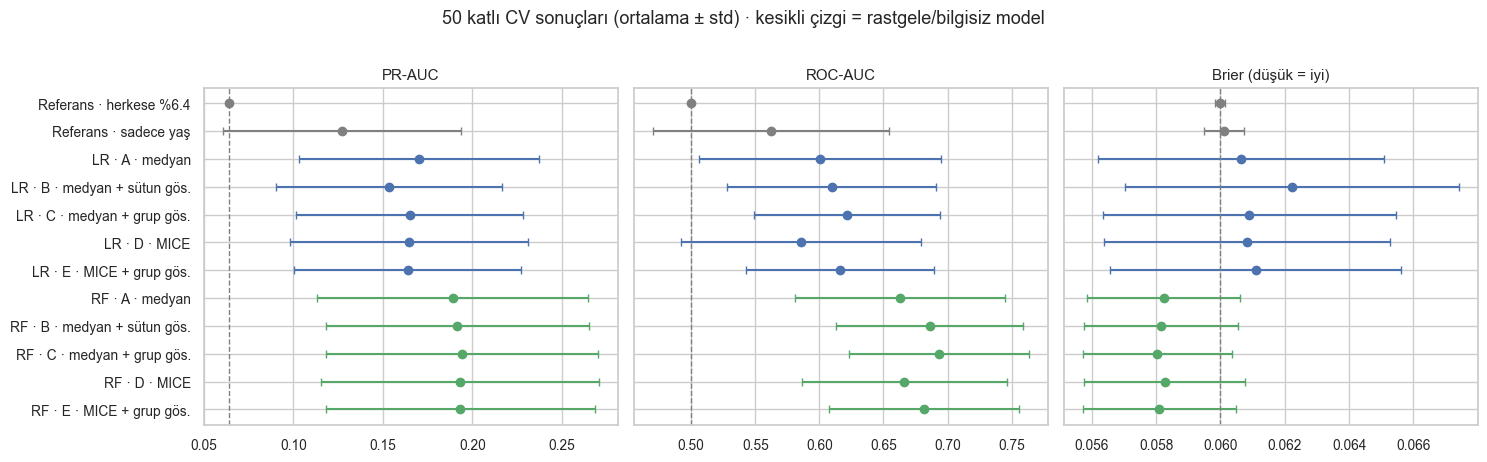

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
order = [(m, c) for m in ["Referans", "LR", "RF"] for c in folds.loc[folds["model"] == m, "düzen"].unique()]
labels = [f"{m} · {c}" for m, c in order]
palette = {"Referans": "grey", "LR": sns.color_palette()[0], "RF": sns.color_palette()[2]}

for ax, metric in zip(axes, ["PR-AUC", "ROC-AUC", "Brier"]):
    for i, (m, c) in enumerate(order):
        v = folds.loc[(folds["model"] == m) & (folds["düzen"] == c), metric]
        ax.errorbar(v.mean(), i, xerr=v.std(), fmt="o", color=palette[m], capsize=3)
    ax.set_title(metric + (" (düşük = iyi)" if metric == "Brier" else ""))
    ax.invert_yaxis()
axes[0].set_yticks(range(len(order)))
axes[0].set_yticklabels(labels)
axes[0].axvline(y.mean(), ls="--", color="grey", lw=1)
axes[1].axvline(0.5, ls="--", color="grey", lw=1)
axes[2].axvline(y.mean() * (1 - y.mean()), ls="--", color="grey", lw=1)
plt.suptitle("50 katlı CV sonuçları (ortalama ± std) · kesikli çizgi = rastgele/bilgisiz model", y=1.02)
plt.tight_layout()
plt.savefig(FIG / "03_model_karsilastirma.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Gösterge eklemek gerçekten fark yaratıyor mu?

50 katın her birinde, her düzeni **aynı modelin A (göstergesiz medyan)** düzeniyle karşılaştırıyoruz. Katlar birbirinden bağımsız olmadığı için (aynı hastalar farklı katlarda tekrar tekrar kullanılıyor) normal t-testi fazla iyimser olur. Bu yüzden **Nadeau-Bengio düzeltilmiş t-testi** kullanıyoruz.

- **Fark > 0** (PR-AUC, ROC-AUC) veya **fark < 0** (Brier) → A'dan daha iyi
- **"A'dan iyi olduğu kat oranı":** 50 katın kaçında bu düzen kazandı

In [7]:
n = len(y)
n_test = n // 5
rows = []
for mname in MODELS:
    base = folds[(folds["model"] == mname) & (folds["düzen"] == "A · medyan")].set_index("kat")
    for cname in CONFIGS:
        if cname.startswith("A"):
            continue
        cur = folds[(folds["model"] == mname) & (folds["düzen"] == cname)].set_index("kat")
        row = {"model": mname, "düzen": cname}
        for metric in ["PR-AUC", "ROC-AUC", "Brier"]:
            d = cur[metric] - base[metric]
            diff, p = corrected_ttest(d, n - n_test, n_test)
            better = (d < 0).mean() if metric == "Brier" else (d > 0).mean()
            row[f"Δ {metric}"] = round(diff, 4)
            row[f"p {metric}"] = round(p, 3)
            row[f"kazanma {metric}"] = f"%{better*100:.0f}"
        rows.append(row)
cmp = pd.DataFrame(rows)
cmp.to_csv(TAB / "03_gosterge_karsilastirma.csv", index=False, encoding="utf-8-sig")
cmp

,model,düzen,Δ PR-AUC,p PR-AUC,kazanma PR-AUC,Δ ROC-AUC,p ROC-AUC,kazanma ROC-AUC,Δ Brier,p Brier,kazanma Brier
0,LR,B · medyan + sütun gös.,-0.0171,0.320,%28,0.0092,0.756,%60,0.0016,0.166,%22
1,LR,C · medyan + grup gös.,-0.0055,0.565,%46,0.0214,0.248,%70,0.0003,0.634,%46
2,LR,D · MICE,-0.0059,0.274,%20,-0.0148,0.221,%28,0.0002,0.313,%28
3,LR,E · MICE + grup gös.,-0.0067,0.484,%44,0.0160,0.445,%68,0.0005,0.428,%36
4,RF,B · medyan + sütun gös.,0.0026,0.817,%60,0.0230,0.131,%80,-0.0001,0.773,%58
5,RF,C · medyan + grup gös.,0.0050,0.605,%66,0.0301,0.055,%86,-0.0002,0.414,%72
6,RF,D · MICE,0.0041,0.654,%60,0.0033,0.795,%52,0.0000,0.890,%48
7,RF,E · MICE + grup gös.,0.0043,0.685,%58,0.0183,0.265,%68,-0.0001,0.660,%54


## 5. Yorum

**Genel performans: sinyal var ama zayıf.**
- En iyi modeller PR-AUC ≈ **0.19**'a ulaşıyor. Rastgele modelin 0.064'ünün yaklaşık **3 katı**. Yani risk faktörleri biyopsi sonucu hakkında gerçek bir bilgi taşıyor.
- Ama mutlak olarak düşük: model "yüksek riskli" dediği hastaların çoğunda yanılıyor. Sadece yaşı kullanan model bile PR-AUC ≈ 0.13'e ulaşıyor.
- ROC-AUC 0.60–0.70 arasında: klinik açıdan "zayıf–orta" ayırt edicilik.
- **Bu dürüst bir sonuç.** Anket tipi risk faktörleri tek başına biyopsi sonucunu iyi tahmin edemiyor. Literatürde bu veri setiyle çok yüksek doğruluk bildiren çalışmaların önemli bir kısmı Hinselmann/Schiller/Sitoloji testlerini girdi olarak kullanıyor (01'de gösterdiğimiz sızıntı).

**RF, LR'den daha iyi.**
- RF her düzende daha yüksek PR-AUC ve ROC-AUC veriyor. Brier skoru da bilgisiz modelin (0.060) biraz altında.
- **LR'nin Brier skoru bilgisiz modelden kötü veya ona eşit:** Olasılık tahminleri, herkese %6.4 demekten daha isabetli değil. Kalibrasyonu 04'te ayrıntılı inceleyeceğiz.

**Göstergeler: ROC-AUC'u artırma eğiliminde, PR-AUC'u neredeyse hiç değiştirmiyor.**
- RF'de grup göstergeleri (C) ROC-AUC'u A'ya göre ≈ +0.03 artırıyor ve 50 katın %86'sında A'yı geçiyor. Ama düzeltilmiş t-testinde p ≈ 0.055, yani **sınırda, anlamlı değil**. PR-AUC farkı (+0.005) ise ihmal edilebilir.
- **Hiçbir düzen farkı istatistiksel olarak anlamlı değil.** 55 pozitifle küçük farkları ayırt etmek çok zor; bu bir "etki yok" kanıtı değil, "güç yetersiz" sonucu.
- **Neden?** 02'de gördük: HK sorusunu cevaplamayan 108 hastanın hiçbiri pozitif değil. Gösterge, modelin bu grubu **listenin en altına** itmesini sağlıyor. Bu, ROC-AUC'u artırır (negatifleri daha iyi sıralar). PR-AUC ise listenin **en üstüne**, yani en yüksek riskli hastalara odaklanır. Göstergeler orada pek bir şey değiştirmiyor.
- **B (sütun başına gösterge) LR'de PR-AUC'u düşürme eğiliminde** (−0.017, anlamlı değil): 11 göstergenin çoğu birbirinin kopyası (HK, RİA, CYBH sütunlarının göstergeleri neredeyse aynı) ve bu LR'de çoklu bağlantıya yol açıyor. Grup göstergesi (C) aynı bilgiyi tekrarsız veriyor; 05'te SHAP yorumu için de daha temiz.
- **MICE (D, E), medyandan (A, C) belirgin şekilde iyi değil.** Eksik değerleri diğer sütunlardan tahmin etmek, bu veri setinde ek bilgi sağlamıyor. Bunun nedeni, eksikliğin blok halinde olması: HK eksikse RİA ve CYBH de eksik, yani tahmin için kullanılacak bilgi de yok.

## 6. 04 için seçimler

| Model | Neden |
|---|---|
| **RF · C (medyan + grup göstergesi)** | En iyi genel performans; ana model |
| **RF · A (medyan, göstergesiz)** | Göstergenin etkisini kalibrasyon ve karar eğrisinde görmek için referans |
| **LR · C** | Yorumlanabilir karşılaştırma modeli; kalibrasyon sorununu incelemek için |

04'te bu modellerin **olasılıklarının ne kadar güvenilir olduğuna** (kalibrasyon), **klinik faydasına** (karar eğrisi) ve **bootstrap güven aralıklarına** bakacağız.